# AISO Learning unit 3: Computational Problems
# Practical: Using Best-First Search and brute-force algorithm to solve classical computational problems 
 
 
## Aims of this practical workbook

1. To build your python **skills** and **confidence** with AI Search Algorithms. 
    - Implement Best first search algorithm exapmple provided in the slides.
    - Understand , implement and modify Brute Force Search Algorithm 
    - To Develop your searching skills using Depth First Search Algorithm .  
2. To give you hands-on experience of **you need to extend and modify**  algorithms to different contexts

### Task 1: Best-First Search Implementation
Fill in the following Python code the missing areas based on pseudocode on the lecture slides.

In [6]:
import heapq  # heapq provides a priority queue (min-heap) data structure

# Define the graph using adjacency lists
graph = {
    'A': ['B', 'D', 'C'],
    'B': ['E', 'A'],
    'C': ['E', 'F', 'A'],
    'D': ['F', 'A'],
    'E': ['H', 'B', 'C'],
    'F': ['G', 'C', 'D'],
    'H': ['G', 'E'],
    'G': ['H', 'F']
}

# Heuristic values (estimated cost from node to goal)
heuristic = {
    'A': 40, 'B': 32, 'C': 25, 'D': 35,
    'E': 19, 'F': 17, 'H': 10, 'G': 0
}

def best_first_search(start, goal):
    visited = set()
    
    # Priority queue (min-heap) stores tuples: (heuristic, node, path)
    # heapq ensures that the node with the smallest heuristic (best node)
    # is always popped first, giving us an efficient way to pick the next node.
    priority_queue = []
    heapq.heappush(priority_queue, (heuristic[start], start, [start]))  # Push start node

    while priority_queue:
        # Pop the node with the lowest heuristic value
        h, current, path = heapq.heappop(priority_queue)

###############################################
        ## Missing code here
###############################################
        if current in visited:
            continue
            
        print(f"Visiting: {current} (h={h}) | Path so far: {path}")

        # Check if we reached the goal and return the path variable
###############################################
        ## Missing code here
###############################################
        visited.add(current)

        if current == goal:
            return path
        # Explore neighbors
        for neighbor in graph[current]:
            if neighbor not in visited:
                # Push neighbor into the priority queue
                # The heap keeps the frontier sorted automatically by heuristic value
                heapq.heappush(priority_queue, (heuristic[neighbor], neighbor, path + [neighbor]))

    print("Goal not reachable.")
    return None

# Run the search
path = best_first_search('A', 'G')
print("\nBest-First Search Path:", " → ".join(path))
### Solution must be: A → C → F → G

Visiting: A (h=40) | Path so far: ['A']
Visiting: C (h=25) | Path so far: ['A', 'C']
Visiting: F (h=17) | Path so far: ['A', 'C', 'F']
Visiting: G (h=0) | Path so far: ['A', 'C', 'F', 'G']

Best-First Search Path: A → C → F → G


# Brute Force Algorithm and Travel Salesman Problem

A **Brute Force Algorithm** is a straightforward approach to solving problems based on trial and error. It tries all possible solutions to find the correct one, without using any shortcuts or optimizations. The algorithm systematically explores every possible combination or path in the solution space until it finds the optimal or correct answer.

### Key Characteristics:

- **Exhaustive Search:** It checks all possible solutions or configurations.
- **Simple to Implement:** Often easy to write and understand.
- **Inefficient:** Typically, it has a high time complexity, often exponential, making it impractical for large input sizes.

### Time Complexity:
- Brute force algorithms tend to have poor time complexity, often O(n!), O(2<sup>n</sup>), or O(n<sup>2</sup>), depending on the problem size.

In [7]:
pip install matplotlib networkx pandas

Defaulting to user installation because normal site-packages is not writeable
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 67.5 MB/s  0:00:00
Note: you may need to restart the kernel to use updated packages.


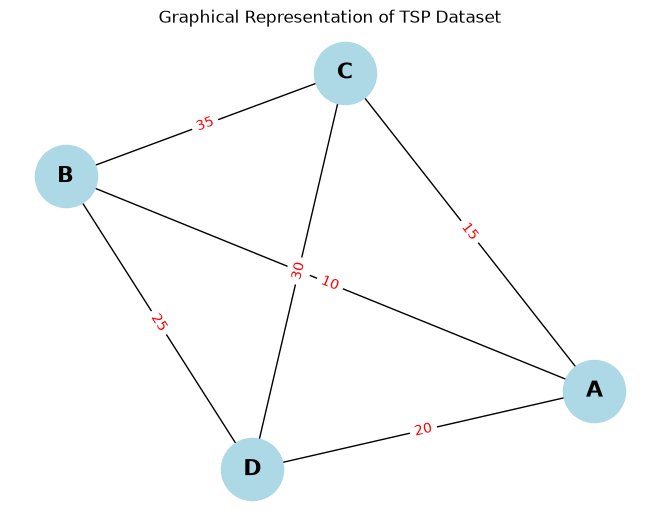

In [8]:
import networkx as nx
import matplotlib.pyplot as plt

# Create a graph
G = nx.Graph()

# Define the distances (edges) based on the dataset
edges = [
    ('A', 'B', 10),
    ('A', 'C', 15),
    ('A', 'D', 20),
    ('B', 'C', 35),
    ('B', 'D', 25),
    ('C', 'D', 30)
]

# Add edges to the graph
for edge in edges:
    G.add_edge(edge[0], edge[1], weight=edge[2])

# Draw the graph
pos = nx.spring_layout(G)  # positions for all nodes
nx.draw(G, pos, with_labels=True, node_size=2000, node_color='lightblue', font_size=16, font_weight='bold')
edge_labels = nx.get_edge_attributes(G, 'weight')
nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, font_color='red')

# Show the plot
plt.title('Graphical Representation of TSP Dataset')
plt.show()

## Travel Salesman Problem Solve Using BruteForce Algorithm

### Requiremnent :
- Agent requires to visit all cities at least once and return to the starting point.

#### Nodes:
**A, B, C, and D** represent the cities.

#### Edges:

- Each line connecting the cities represents the distance between them.
- The distances (weights) are labeled on the edges:


- **A to B:** 10
- **A to C:** 15
- **A to D:** 20
- **B to C:** 35
- **B to D:** 25
- **C to D:** 30

In [9]:
from itertools import permutations  # Import permutations to generate all possible orders of cities

# Define distances between cities (undirected)
# Each tuple represents a pair of cities and the distance between them
distances = {
    ('A', 'B'): 10,
    ('A', 'C'): 15,
    ('A', 'D'): 20,
    ('B', 'C'): 35,
    ('B', 'D'): 25,
    ('C', 'D'): 30
}

# Function to calculate the total distance of a given route
def calculate_distance(route):
    total_distance = 0  # Initialize total distance to 0
    
    # Loop through the route to sum distances between consecutive cities
    for i in range(len(route) - 1):  # len(route)-1 because last city is paired with next
        city_pair = (route[i], route[i + 1])          # current step (city1 -> city2)
        reverse_pair = (route[i + 1], route[i])      # reverse order in case distance is stored the other way
        # Add the distance to total_distance; use 0 if no distance found (shouldn't happen here)
        total_distance += distances.get(city_pair) or distances.get(reverse_pair)
        
    return total_distance  # Return the total distance of this route

# Brute-force TSP function
def tsp_brute_force(cities, start_city='A'):
    min_distance = float('inf')  # Initialize the minimum distance as infinity
    best_route = None            # Initialize the best route as None
    
    # Exclude the start city from permutations, because it will always be the first city
    other_cities = [city for city in cities if city != start_city]
    
    # Generate all possible orders of visiting the other cities
    for perm in permutations(other_cities):
        # Build the full route: start city -> permutation of other cities -> back to start city
        route = (start_city,) + perm + (start_city,)
        
        # Calculate the total distance of this route
        current_distance = calculate_distance(route)

        #Print progress
        print("Checking route:", end=' ')
        print(route, end=' ') 
        print("... with distance = ", current_distance) 
        
        # Check if this route has a smaller distance than the current minimum
        if current_distance < min_distance:
            min_distance = current_distance  # Update the minimum distance
            best_route = route               # Update the best route
    
    return best_route, min_distance  # Return the best route and its total distance

# List of cities
cities = ['A', 'B', 'C', 'D']

# Find the optimal route starting and ending at 'A'
best_route, min_distance = tsp_brute_force(cities, start_city='A')

# Print the best route and the minimum distance
print()
print(f'The best route starting and ending at A is: {best_route} with a total distance of: {min_distance}')


Checking route: ('A', 'B', 'C', 'D', 'A') ... with distance =  95
Checking route: ('A', 'B', 'D', 'C', 'A') ... with distance =  80
Checking route: ('A', 'C', 'B', 'D', 'A') ... with distance =  95
Checking route: ('A', 'C', 'D', 'B', 'A') ... with distance =  80
Checking route: ('A', 'D', 'B', 'C', 'A') ... with distance =  95
Checking route: ('A', 'D', 'C', 'B', 'A') ... with distance =  95

The best route starting and ending at A is: ('A', 'B', 'D', 'C', 'A') with a total distance of: 80


<div class="alert alert-warning" style="color:black">
<h1> Task 2: Solve Knapsack Problem Using Brute Force Algorithm </h1>

**Problem Statement:****  
You are given a set of items, each with a weight and a value. Your goal is to determine the maximum value that can be carried in a knapsack with a limited capacity. You can either include an item in the knapsack or leave it out, but you cannot break items or take fractional amounts. The brute force approach involves checking all possible combinations of items.

**Items Table:**

| Item   | Weight | Value |
|--------|--------|-------|
| Item 1 | 2      | 3     |
| Item 2 | 3      | 4     |
| Item 3 | 4      | 5     |
| Item 4 | 5      | 6     |

</div>


In [35]:
import pandas as pd
import itertools

# Load dataset from CSV
def load_data(file_path):
    try:
        df = pd.read_csv(file_path)
        return df
    except Exception as e:
        print(f"Error loading data: {e}")
        return None

# Brute force solution to the Knapsack Problem 
 ###############################################
        ## [[your code goes here]] 
        ## Hint: Define a knapsack_bruteforce function called in the main
 ###############################################
def knapsack_bruteforce(weights, values, capacity):

    numItems = itertools.permutations(i for i in range(len(weights)))
    bestCombination = []
    bestValue = 0
    for i in numItems:
        totalValue = 0
        totalWeight = 0
        currentCombination = []
        for x in i:
            if totalWeight < capacity and (weights[x] + totalWeight) <= capacity:
                totalValue += values[x]
                totalWeight +=  weights[x]
                currentCombination.append(x)
        
        if totalValue > bestValue:
            bestValue = totalValue
            bestCombination = currentCombination
    
    return bestValue, bestCombination

# Main function
def main():
    # File path for the dataset
    file_path = 'knapsack_dataset.xls'  # Ensure this CSV file exists

    # Load data
    df = load_data(file_path)
    if df is None:
        return  # Exit if data loading failed

    # Check if the necessary columns are in the dataset
 ###############################################
        ## [[your code goes here]]
 ###############################################
    if df['Weight'] is None:
        return
    if df['Value'] is None:
        return
    # Get weights and values
    weights = df['Weight'].values
    values = df['Value'].values

    # User input for knapsack capacity should not be more than 10
 ###############################################
        ## [[your code goes here]]
 ###############################################
    capacity = 11
    while capacity > 10:
        capacity = int(input("Input a capacity less than 10: "))
        
    # Solve the Knapsack Problem using brute force
    max_value, best_combination = knapsack_bruteforce(weights, values, capacity)
    
    # Output the results
    print(f"\nMaximum value that can be obtained: {max_value}")
    print("Items included in the knapsack:")
    for i in best_combination:
        print(f" - {df['Item'][i]} (Weight: {weights[i]}, Value: {values[i]})")

# Run the main function
if __name__ == "__main__":
    main()

Input a capacity less than 10:  8



Maximum value that can be obtained: 10
Items included in the knapsack:
 - Item 2 (Weight: 3, Value: 4)
 - Item 4 (Weight: 5, Value: 6)


 ### For your learning
<div style="background:#F0FFFF;font-size:1em">
    <dl>
        <dd> 1. First try to fill out the spaces which is provided to you.</dd>
        <dd> 2. If you want to write from scratch you can!!! .</dd>
          </dl>
    </div> 

<div class="alert alert-warning" style="color:black">
<h1>Task 3 Solve 8-Puzzle Problem Using DFS </h1>
The 8-puzzle is a sliding puzzle that consists of a 3x3 grid with 8 numbered tiles and one empty space. The objective is to move the tiles around until the puzzle reaches a desired goal configuration. The key challenge in solving this problem is finding a sequence of moves that leads from the start state to the goal state.


<h2>Step-by-Step Problem Formulation:</h2> 
 
 **States (Nodes):**

- Each state of the puzzle is a unique arrangement of the 8 tiles and the empty space. A state is represented as a 3x3 grid or as a list of 9 values, where the empty space is denoted by 0.

 **Initial State:**

- The starting configuration of the puzzle, which can be any arbitrary arrangement of the tiles.
      <table><tr><td>1</td>
    <td>2</td>
    <td>3</td></tr><tr></tr><tr><td>4</td>
    <td>0</td>
    <td>6</td></tr><tr></tr><td>7</td>
    <td>5</td>
    <td>8</td><tr></tr></table>


 **Goal State:**

- The target configuration where the tiles are ordered correctly (e.g., numbers in ascending order with the empty space at the last position)

  <table><tr><td>1</td>
    <td>2</td>
    <td>3</td></tr><tr></tr><tr><td>4</td>
    <td>5</td>
    <td>6</td></tr><tr></tr><td>7</td>
    <td>8</td>
    <td>0</td><tr></tr></table>
</div.

In [40]:
 ###############################################
        ## [[your code goes here]]
 ###############################################

def parse_action(action):
    match action:
        case 'L':
            return (-1, 0)
        case 'R':
            return (1, 0)
        case 'D':
            return (-1, 1)
        case 'U':
            return (1, 1)
             
def resolve_puzzle(initial_state, goal_state, max_depths=9, index=[1,1]):
    
    moves_list = ['L','R','U','D']
    working_state = initial_state
    sequences = set()
    
    while working_state != goal_state:
        possible_moves = moves_list
        sequence = ""
        depth = 0
        while depth < max_depths:
            action = possible_moves[-1]
            displacement, axis = parse_action(action)
            while ((sequence + action) in sequences) and len(possible_moves) > 0:
                action = possible_moves.pop()

            if (sequence + action) in sequences:
                depths += 9
                continue
            
            if index[axis] + displacement > 2 or index[axis] + displacement < 0:
                possible_moves.pop()
    
            else:
                sequence += action
                depth += 1
                displaced_index = index
                displaced_index[axis] += displacement
                working_state[index[0]][index[1]] = working_state[displaced_index[0]][displaced_index[1]]
                working_state[displaced_index[0]][displaced_index[1]] =  0

            if working_state == goal_state:
                break
        
        sequences.add(sequence)
    
        return sequence
    

initial_state = [[1,2,3],[4,0,6],[7,5,8]]
goal_state = [[1,2,3],[4,5,6],[7,8,0]]
max_depths = 9
key = [1,1]

print(resolve_puzzle(initial_state, goal_state, max_depths, key))

TypeError: 'tuple' object does not support item assignment

 ### Hints
<div style="background:#F0FFFF;font-size:1em">
    <dl>
        <dd> 1. Explore the state space by taking one possible move and going as deep as possible along that path before backtracking..</dd>
        <dd> 2. It will keep track of visited states to avoid repeating states and getting stuck in loops.</dd>
          </dl>
    </div> 

<div style="background-color: #E6E6FA ; color: red; padding: 10px; border-radius: 5px;font-weight: bold">
  Congratulations if you have completed please note that this worksheet is subject to updates in the upcoming week. I will be adding more tasks and making additional changes.
</div>